这份数据是谁
分析对象：车辆的空间-时间行为
    1 车辆都去过哪些网格（到访占比）
    2 热点在哪里：15 号站台（类比西塔）+ 加权中心
    3 距离阈值：离热点的距离 ECDF、各半径覆盖车辆
    4 什么时候在热点：各小时热点 500m 内去重车辆
    5 城市潮汐：24h × 区域（核心/内环/外环/机场）占比矩阵
    6 各时刻车在哪些区域（小多图）

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle

import taxi_common as tc

SCRIPT = "这份数据是谁"
tc.AUTHOR = "薛宏博 2428324276"
SOURCE = tc.source_line(SCRIPT)
tc.apply_theme()

dwd = pd.read_pickle(tc.CACHE_DIR / "dwd_grid.pkl")
dim_stand = pd.read_pickle(tc.CACHE_DIR / "dim_stand.pkl")

# haversine 距离（米）
def haversine(lng1, lat1, lng2, lat2):
    R = 6371000
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp = np.radians(lat2 - lat1)
    dl = np.radians(lng2 - lng1)
    a = np.sin(dp/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 2*R*np.arcsin(np.sqrt(a))

# 市中心与热点（15 号站台，类比西塔）
CITY = (-8.610, 41.150)
HOT = (float(dim_stand.loc[dim_stand.STAND==15, "lng"].iloc[0]),
       float(dim_stand.loc[dim_stand.STAND==15, "lat"].iloc[0]))
HOT_RADIUS = 500

In [2]:
# 车辆到访网格
print("车辆到访网格\n")
n_taxi = dwd["TAXI_ID"].nunique()
reach = (dwd.groupby(["gx", "gy"])["TAXI_ID"].nunique()
         .rename("到访车辆").reset_index())
reach["到访车辆占比"] = reach["到访车辆"] / n_taxi
reach = reach.sort_values("到访车辆", ascending=False)
print(f"车辆 {n_taxi} 辆；网格 {len(reach)} 个")
print("到访车辆最多的网格：\n", reach.head(6).to_string(index=False))
per_taxi_grid = dwd.groupby("TAXI_ID")[["gx","gy"]].apply(
    lambda g: g.drop_duplicates().shape[0], include_groups=False)
print(f"\n每辆车到访网格数：中位 {per_taxi_grid.median():.0f}，"
      f"最多 {per_taxi_grid.max()}")

车辆到访网格

车辆 428 辆；网格 298 个
到访车辆最多的网格：
  gx  gy  到访车辆   到访车辆占比
 14  24   422 0.985981
 13  25   408 0.953271
 13  24   400 0.934579
 14  23   394 0.920561
 15  24   383 0.894860
 12  25   378 0.883178

每辆车到访网格数：中位 33，最多 65


In [3]:
# 热点
print("热点（15 号站台）\n")
# 加权中心：按 top5 站台发车趟次加权（类比西塔加权中心）
top5 = dim_stand.sort_values("发车趟次", ascending=False).head(5)
wcx = np.average(top5["lng"], weights=top5["发车趟次"])
wcy = np.average(top5["lat"], weights=top5["发车趟次"])
print("top5 站台：\n", top5[["STAND","lng","lat","发车趟次"]].to_string(index=False))
print(f"加权中心 ({wcx:.4f},{wcy:.4f})；热点 15 号站台 ({HOT[0]:.4f},{HOT[1]:.4f})")

热点（15 号站台）

top5 站台：
  STAND       lng       lat  发车趟次
    15 -8.585667 41.148558  4958
    57 -8.610849 41.145651  3225
     9 -8.606475 41.144625  2265
    23 -8.612568 41.145984  2207
    18 -8.619840 41.148009  2022
加权中心 (-8.6032,41.1468)；热点 15 号站台 (-8.5857,41.1486)


In [4]:
# 距离阈值 ECDF
print("距离阈值\n")
dhot = haversine(dwd["lng0"].values, dwd["lat0"].values, HOT[0], HOT[1])
dwd["dhot"] = dhot
# 每辆车到热点的最近距离
user_min = dwd.groupby("TAXI_ID")["dhot"].min().clip(lower=10)
radii = [100, 200, 300, 500, 1000, 2000, 5000]
cover = pd.DataFrame({"半径米": radii})
cover["覆盖车辆占比"] = [np.mean(user_min <= r) for r in radii]
print(cover.to_string(index=False))
p500 = np.mean(user_min <= 500)

距离阈值

 半径米   覆盖车辆占比
 100 0.696262
 200 0.728972
 300 0.740654
 500 0.768692
1000 0.857477
2000 0.995327
5000 0.997664


In [5]:
# 热点各小时
print("热点各小时\n")
near = dwd[dwd["dhot"] <= HOT_RADIUS]
hot_hourly = (near.groupby("hour")["TAXI_ID"].nunique()
              .reindex(range(24), fill_value=0))
first_hour = (near.groupby("TAXI_ID")["ts_local"].min().dt.hour
              .value_counts().reindex(range(24), fill_value=0))
print("热点 500m 内各小时去重车辆：\n", hot_hourly.to_string())
peak = int(hot_hourly.idxmax())
print(f"峰值 {peak} 点 {hot_hourly.max()} 辆")

热点各小时

热点 500m 内各小时去重车辆：
 hour
0      46
1      46
2      17
3      18
4      16
5      30
6      26
7      44
8      73
9     115
10    123
11    106
12    114
13    115
14    115
15    119
16    104
17     99
18     83
19     98
20     72
21     80
22     56
23     47
峰值 10 点 123 辆


In [6]:
# 区域划分 + 潮汐
print("区域划分与潮汐\n")
dcity = haversine(dwd["lng0"].values, dwd["lat0"].values, CITY[0], CITY[1])
AIRPORT = (-8.681, 41.248)
dair = haversine(dwd["lng0"].values, dwd["lat0"].values, AIRPORT[0], AIRPORT[1])
def zone(d, da):
    if da < 1000: return "机场"
    if d < 1500: return "核心区"
    if d < 4000: return "内环"
    if d < 8000: return "外环"
    return "远郊"
zones = [zone(a, b) for a, b in zip(dcity, dair)]
dwd["区域"] = zones
ZORDER = ["核心区", "内环", "外环", "机场", "远郊"]
# 趟次占比：每小时内各区域占比（列合计 100%）
t = dwd.groupby(["区域", "hour"]).size().unstack(fill_value=0).reindex(ZORDER).fillna(0)
ratio = t / t.sum(axis=0)
print("各区域总趟次占比：\n",
      (t.sum(axis=1)/t.values.sum()).round(3).to_string())
print("\n区域×小时占比矩阵（取 4 个时刻）：")
print(ratio[[4,10,17,23]].round(2).to_string())

区域划分与潮汐

各区域总趟次占比：
 区域
核心区    0.434
内环     0.436
外环     0.122
机场     0.000
远郊     0.008

区域×小时占比矩阵（取 4 个时刻）：
hour    4     10    17    23
区域                          
核心区   0.71  0.36  0.41  0.51
内环    0.20  0.50  0.46  0.37
外环    0.08  0.13  0.13  0.11
机场    0.00  0.00  0.00  0.00
远郊    0.01  0.01  0.01  0.00


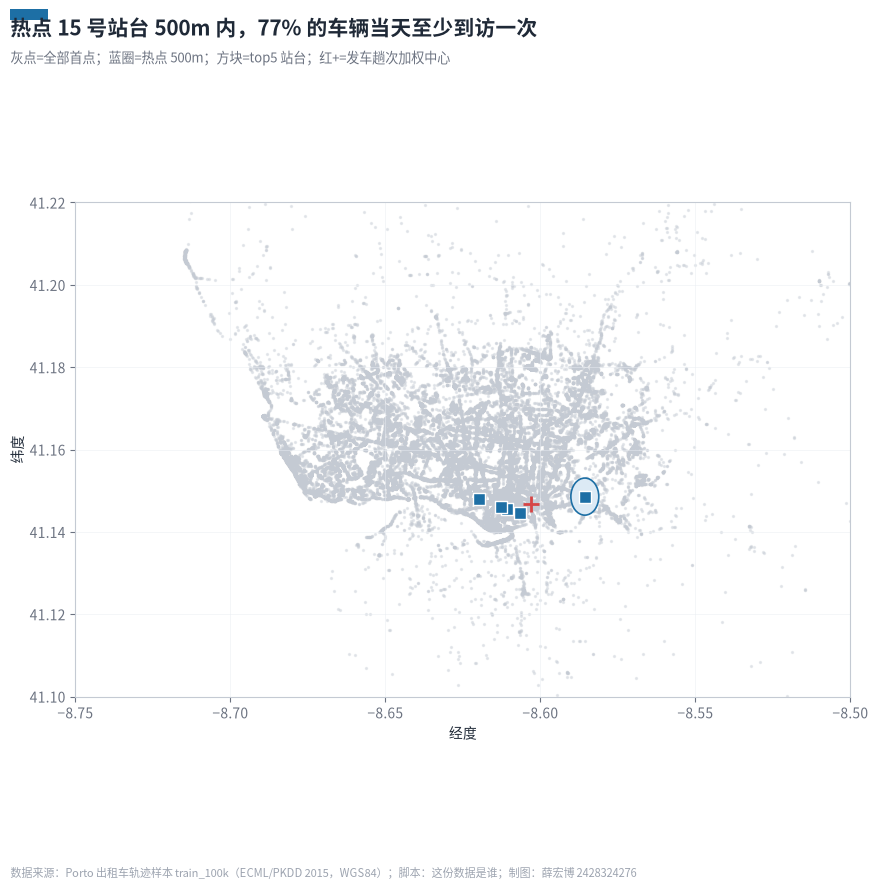

In [7]:
# 热点空间
fig, ax = plt.subplots(figsize=(10, 9), dpi=100)
# 全部首点淡灰
ax.scatter(dwd["lng0"], dwd["lat0"], s=2, color=tc.GRAY, alpha=.35, zorder=1)
# 热点 500m 圈
c = plt.Circle(HOT, 500/111000, facecolor=tc.MAIN_LIGHT,
               edgecolor=tc.MAIN, lw=1.2, zorder=2)
ax.add_patch(c)
# top5 站台
for _, r in top5.iterrows():
    ax.scatter(r["lng"], r["lat"], s=80, marker="s",
               color=tc.MAIN, edgecolor="white", zorder=4)
ax.scatter(wcx, wcy, marker="+", s=120, color=tc.RED, lw=2, zorder=5)
ax.set_aspect(1/np.cos(np.radians(41.15)))
ax.set_xlim(-8.75, -8.5)
ax.set_ylim(41.10, 41.22)
ax.set_xlabel("经度"); ax.set_ylabel("纬度")
tc.finish(
    fig,
    f"热点 15 号站台 500m 内，{p500:.0%} 的车辆当天至少到访一次",
    "灰点=全部首点；蓝圈=热点 500m；方块=top5 站台；红+=发车趟次加权中心",
    SOURCE, "D4_01_热点空间.png")
plt.show()

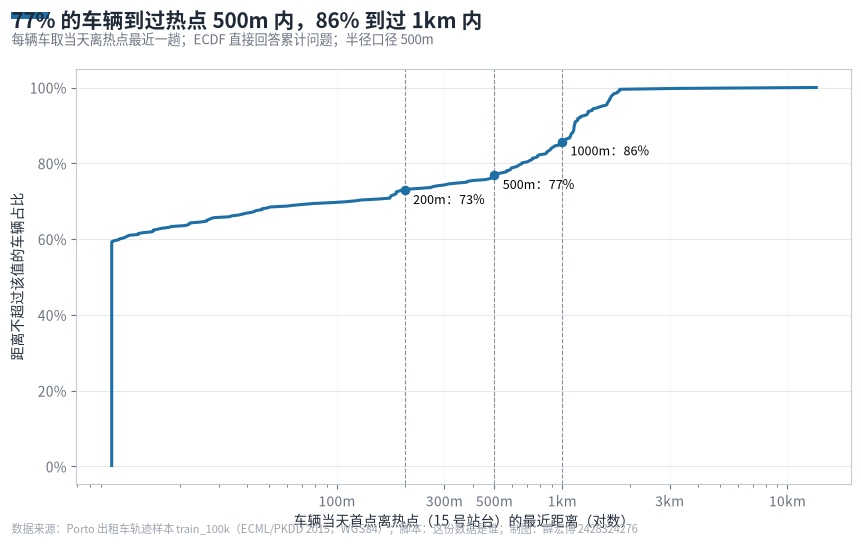

In [8]:
# 距离 ECDF
fig, ax = plt.subplots(figsize=(10, 5.4), dpi=100)
xs = np.sort(user_min.values); ys = np.arange(1,len(xs)+1)/len(xs)
ax.plot(xs, ys, color=tc.MAIN, lw=2.2)
ax.set_xscale("log")
ax.set_xticks([100,300,500,1000,3000,10000])
ax.set_xticklabels(["100m","300m","500m","1km","3km","10km"])
for r in [200,500,1000]:
    p = np.mean(user_min<=r)
    ax.axvline(r, color=tc.GRAY_DARK, lw=.8, ls="--")
    ax.scatter(r, p, color=tc.MAIN, s=35, zorder=3)
    ax.annotate(f"{r}m：{p:.0%}", (r,p), xytext=(6,-10),
                textcoords="offset points", fontsize=9)
ax.yaxis.set_major_formatter("{x:.0%}")
ax.set_xlabel("车辆当天首点离热点（15 号站台）的最近距离（对数）")
ax.set_ylabel("距离不超过该值的车辆占比")
ax.grid(axis="y", color=tc.GRAY, lw=.6)
tc.finish(
    fig,
    f"{p500:.0%} 的车辆到过热点 500m 内，{np.mean(user_min<=1000):.0%} 到过 1km 内",
    "每辆车取当天离热点最近一趟；ECDF 直接回答累计问题；半径口径 500m",
    SOURCE, "D4_02_离热点距离.png")
plt.show()

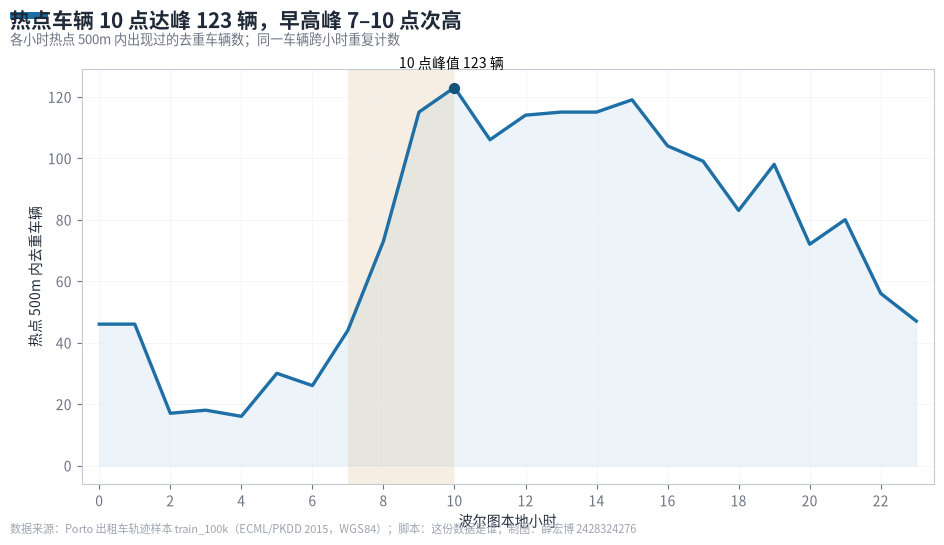

In [9]:
# 热点小时
fig, ax = plt.subplots(figsize=(11, 5.4), dpi=100)
ax.fill_between(range(24), hot_hourly.values, color=tc.MAIN_LIGHT, alpha=.5)
ax.plot(range(24), hot_hourly.values, color=tc.MAIN, lw=2.4)
ax.scatter(peak, hot_hourly[peak], color=tc.MAIN_DARK, s=50, zorder=3)
ax.annotate(f"{peak} 点峰值 {hot_hourly[peak]} 辆", (peak, hot_hourly[peak]),
            xytext=(-40,14), textcoords="offset points")
ax.axvspan(7,10, color=tc.AMBER, alpha=.12, lw=0)
ax.set_xticks(range(0,24,2))
ax.set_xlabel("波尔图本地小时"); ax.set_ylabel("热点 500m 内去重车辆")
ax.set_xlim(-.5,23.5)
tc.finish(
    fig,
    f"热点车辆 {peak} 点达峰 {hot_hourly[peak]} 辆，早高峰 7–10 点次高",
    "各小时热点 500m 内出现过的去重车辆数；同一车辆跨小时重复计数",
    SOURCE, "D4_03_热点各小时.png")
plt.show()

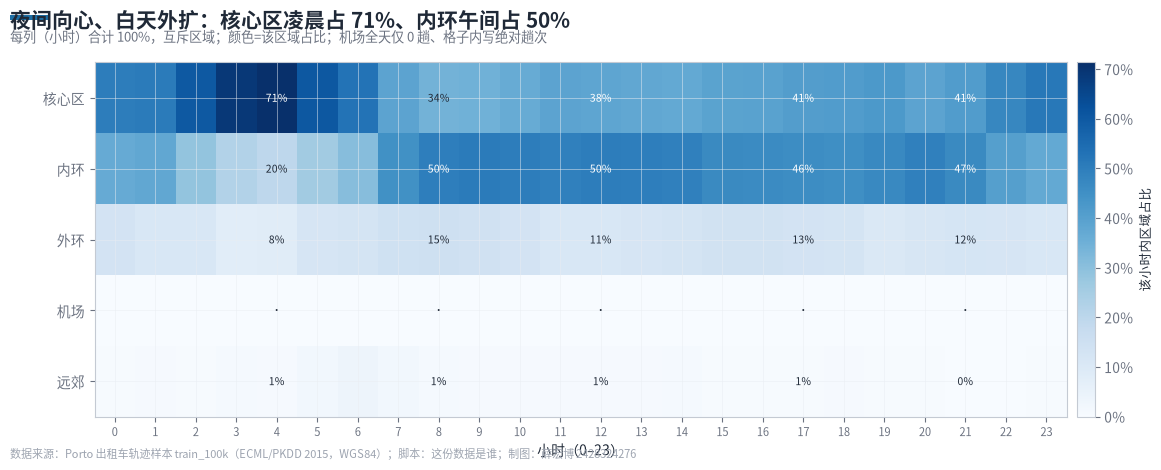

In [10]:
# 潮汐矩阵
fig, ax = plt.subplots(figsize=(13, 4.6), dpi=100)
im = ax.imshow(ratio.values, aspect="auto", cmap="Blues",
               norm=Normalize(0, max(.5, ratio.values.max())))
ax.set_xticks(range(24)); ax.set_xticklabels(range(24), fontsize=8)
ax.set_yticks(range(len(ZORDER))); ax.set_yticklabels(ZORDER)
# 关键时刻写百分数（机场样本少，改写绝对趟次）
for i, name in enumerate(ZORDER):
    for h in [4,8,12,17,21]:
        v = ratio.loc[name,h]
        if name == "机场":
            nt = t.loc["机场", h]
            txt = f"{int(nt)}趟" if nt > 0 else "·"
            ax.text(h, i, txt, ha="center", va="center", fontsize=7, color=tc.INK)
        else:
            ax.text(h, i, f"{v:.0%}", ha="center", va="center",
                    fontsize=7.5, color=tc.INK if v<.35 else "white")
ax.set_xlabel("小时（0–23）")
cbar = fig.colorbar(im, ax=ax, fraction=.025, pad=.01)
cbar.ax.yaxis.set_major_formatter("{x:.0%}")
cbar.set_label("该小时内区域占比", fontsize=9)
tc.finish(
    fig,
    f"夜间向心、白天外扩：核心区凌晨占 {ratio.loc['核心区',4]:.0%}、内环午间占 {ratio.loc['内环',12]:.0%}",
    f"每列（小时）合计 100%，互斥区域；颜色=该区域占比；机场全天仅 {int(t.loc['机场'].sum())} 趟、格子内写绝对趟次",
    SOURCE, "D4_04_城市潮汐矩阵.png")
plt.show()

完成：图片已保存至 C:\Users\l1513\PycharmProjects\data-analysis-project-2026\image


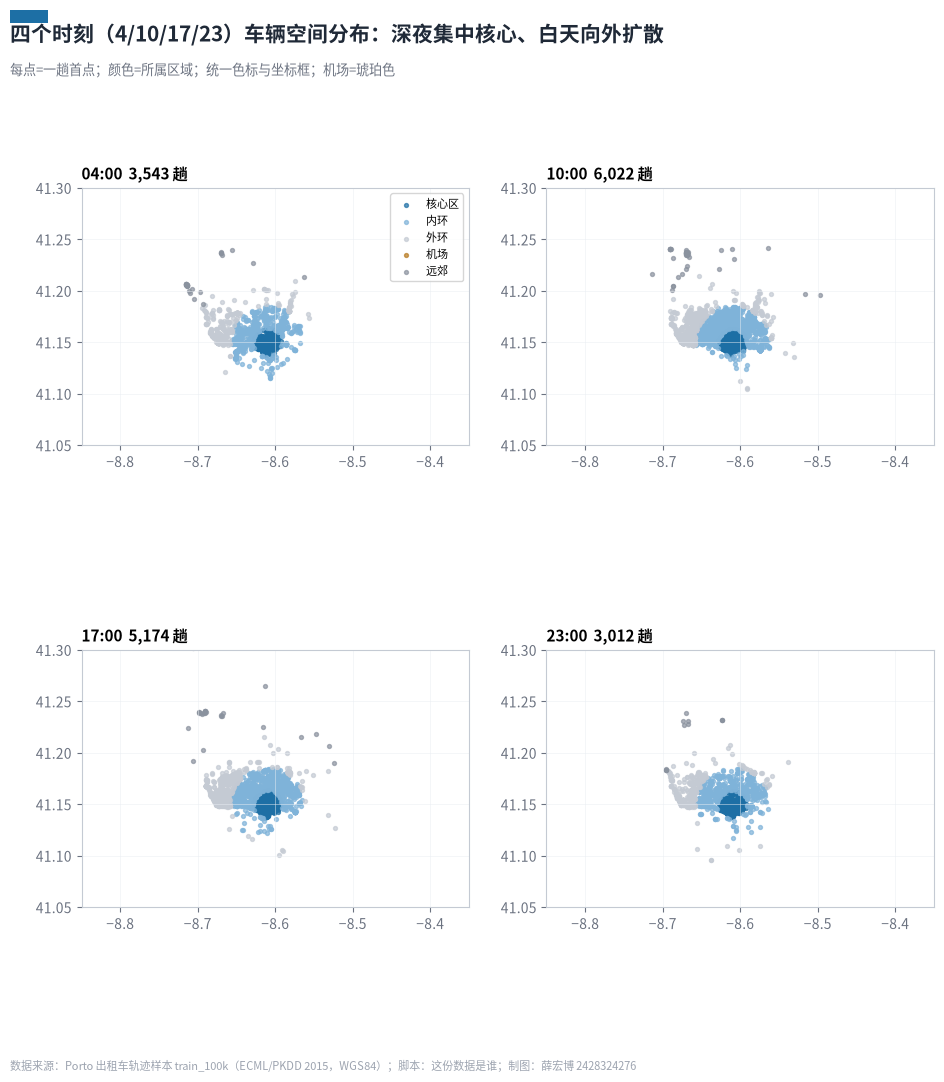

In [11]:
# 各时刻小多图
fig, axes = plt.subplots(2, 2, figsize=(11, 11), dpi=100)
for ax, h in zip(axes.flat, [4, 10, 17, 23]):
    sub = dwd[dwd["hour"]==h]
    for z, color in zip(ZORDER, [tc.MAIN, tc.MAIN_MID, tc.GRAY, tc.AMBER, tc.GRAY_DARK]):
        s = sub[sub["区域"]==z]
        ax.scatter(s["lng0"], s["lat0"], s=8, color=color, label=z, alpha=.7)
    ax.set_aspect(1/np.cos(np.radians(41.15)))
    ax.set_xlim(-8.85,-8.35); ax.set_ylim(41.05,41.30)
    ax.set_title(f"{h:02d}:00  {len(sub):,} 趟", loc="left", fontsize=11)
axes[0,0].legend(fontsize=8, loc="upper right")
tc.finish(
    fig,
    f"四个时刻（4/10/17/23）车辆空间分布：深夜集中核心、白天向外扩散",
    "每点=一趟首点；颜色=所属区域；统一色标与坐标框；机场=琥珀色",
    SOURCE, "D4_05_各时刻分布.png")

print("完成：图片已保存至", tc.IMAGE_DIR)
plt.show()